In [33]:
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.datasets import load_wine
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text  import CountVectorizer, HashingVectorizer
import matplotlib.pyplot as plt
import seaborn as sb

In [14]:
wine = load_wine()
df = pd.DataFrame(wine.data,columns = wine.feature_names)
df['target'] = wine.target
dir(wine)

['DESCR', 'data', 'feature_names', 'frame', 'target', 'target_names']

In [13]:
df.head(10)

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0
5,14.20,1.76,2.45,15.2,112.0,3.27,3.39,0.34,1.97,6.75,1.05,2.85,1450.0,0
6,14.39,1.87,2.45,14.6,96.0,2.50,2.52,0.30,1.98,5.25,1.02,3.58,1290.0,0
7,14.06,2.15,2.61,17.6,121.0,2.60,2.51,0.31,1.25,5.05,1.06,3.58,1295.0,0
8,14.83,1.64,2.17,14.0,97.0,2.80,2.98,0.29,1.98,5.20,1.08,2.85,1045.0,0
9,13.86,1.35,2.27,16.0,98.0,2.98,3.15,0.22,1.85,7.22,1.01,3.55,1045.0,0


In [26]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 14 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   alcohol                       178 non-null    float64
 1   malic_acid                    178 non-null    float64
 2   ash                           178 non-null    float64
 3   alcalinity_of_ash             178 non-null    float64
 4   magnesium                     178 non-null    float64
 5   total_phenols                 178 non-null    float64
 6   flavanoids                    178 non-null    float64
 7   nonflavanoid_phenols          178 non-null    float64
 8   proanthocyanins               178 non-null    float64
 9   color_intensity               178 non-null    float64
 10  hue                           178 non-null    float64
 11  od280/od315_of_diluted_wines  178 non-null    float64
 12  proline                       178 non-null    float64
 13  targe

In [ ]:
print(wine.DESCR)

In [20]:
wine.feature_names

['alcohol',
 'malic_acid',
 'ash',
 'alcalinity_of_ash',
 'magnesium',
 'total_phenols',
 'flavanoids',
 'nonflavanoid_phenols',
 'proanthocyanins',
 'color_intensity',
 'hue',
 'od280/od315_of_diluted_wines',
 'proline']

In [28]:
X = df.drop('target', axis = 1 )
y = df.target

In [53]:
X_train, X_test, y_train, y_test = train_test_split(X , y , test_size=0.2)

In [54]:
# yp1 = pip1.fit(X_train,y_train)
model1  = MultinomialNB()
model1.fit(X_train,y_train)
model2 = GaussianNB()
model2.fit(X_train,y_train)

,priors,None
,var_smoothing,1e-09


In [55]:
yp1 = model1.predict(X_test)
yp2 = model2.predict(X_test)

In [56]:
sc1 = model1.score(X_test,y_test)
sc2 = model2.score(X_test,y_test)

<Axes: >

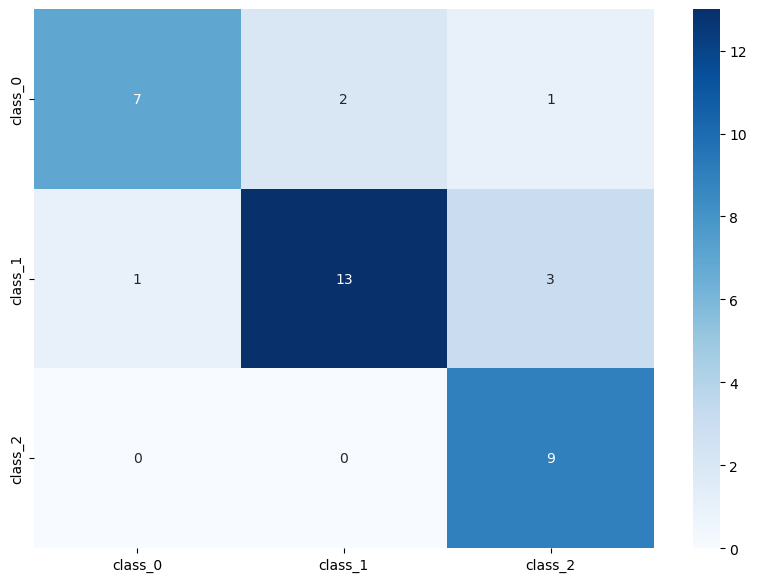

In [57]:
con = confusion_matrix(y_test,yp1)
plt.figure(figsize = (10,7))
plt.xlabel("Predicted")
plt.ylabel("Truth")
species_labels = ['class_0', 'class_1', 'class_2']
sb.heatmap(con,annot=True, xticklabels=species_labels,yticklabels=species_labels,cmap='Blues')

In [58]:
print("first model score : ", sc1)
print("second model score : ", sc2)


first model score :  0.8055555555555556
second model score :  0.9444444444444444
